# Projection model

This notebook will show the machine learning prediction statistics for each player's 2025-26 fantasy point total using only data from earlier seasons, and compares them with two simple baselines: last season's total (draft strategy 1) and a 3-season weighted average (strategy 2).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # make the project root importable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import config

from matplotlib.ticker import StrMethodFormatter
from sklearn.inspection import permutation_importance

from src.features import MODEL_FEATURES, TARGET, build_base_table, build_model_table, split_by_season
from src.model import evaluate, train_random_forest, train_xgboost, tune_random_forest, tune_xgboost, project_with_range, scale_range, range_coverage, calibrate_range_factor

sns.set_theme(style="whitegrid")

In [2]:
model_table = build_model_table()
train, test = split_by_season(model_table)
print(f"Train: {len(train)} rows | Test: {len(test)} rows ({config.TEST_SEASON})")

Train: 1358 rows | Test: 347 rows (2025-26)


## Baselines

In [3]:
results = pd.DataFrame({
    "Last season (strategy 1)": evaluate(test[TARGET], test["FANTASY_PTS_LAG1"]),
    "3-season average (strategy 2)": evaluate(test[TARGET], test["FANTASY_PTS_AVG3"]),
}).T
results.round(0)

,MAE,RMSE
Last season (strategy 1),740.0,974.0
3-season average (strategy 2),740.0,956.0


## Model parameter tuning with time-based cross-validation

Settings for both models are chosen using only the training seasons: train on earlier seasons, score on the next one, and average across three rounds. The 2025-26 test season is not used here, it is used only to report the final results below

In [4]:
rf_search = tune_random_forest(train)
xgb_search = tune_xgboost(train)


def cv_summary(search, name, defaults):
    """Cross-validated MAE for the original settings and for the best settings found."""
    scores = pd.DataFrame(search.cv_results_["params"])
    scores["CV MAE"] = -search.cv_results_["mean_test_score"]
    is_default = (scores[list(defaults)] == pd.Series(defaults)).all(axis=1)
    return {
        "Model": name,
        "CV MAE, original settings": scores.loc[is_default, "CV MAE"].iloc[0],
        "CV MAE, tuned": scores["CV MAE"].min(),
        "Best settings": search.best_params_,
    }


tuning = pd.DataFrame([
    cv_summary(rf_search, "Random Forest", {"min_samples_leaf": 5, "max_features": 1.0}),
    cv_summary(xgb_search, "XGBoost", {"max_depth": 4, "learning_rate": 0.05, "n_estimators": 300}),
]).set_index("Model")
pd.set_option("display.max_colwidth", None)
tuning.round(0)

,"CV MAE, original settings","CV MAE, tuned",Best settings
Model,,,
Random Forest,589.0,587.0,"{'max_features': 0.5, 'min_samples_leaf': 5}"
XGBoost,615.0,585.0,"{'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300}"


Tuning barely changed the Random Forest (CV MAE 589 to 587) but improved XGBoost substantially (615 to 585) with shallower trees and a slower learning rate.

## Random Forest
Model settings come from config.py and were chosen by the cross-validation in the tuning section above.

In [5]:
rf = train_random_forest(train)
rf_test_pred = rf.predict(test[MODEL_FEATURES])
results.loc["Random Forest"] = pd.Series(evaluate(test[TARGET], rf_test_pred))

rf_train_mae = evaluate(train[TARGET], rf.predict(train[MODEL_FEATURES]))["MAE"]
print(f"Random Forest MAE on training rows: {rf_train_mae:,.0f}")
results.round(0)

Random Forest MAE on training rows: 393


,MAE,RMSE
Last season (strategy 1),740.0,974.0
3-season average (strategy 2),740.0,956.0
Random Forest,670.0,857.0


The Random Forest misses by 670 points on average, about 9% better than either baseline which are both the same (740), and its RMSE is about 10% lower (857 vs. 956 for the weighted strategy), so it also makes fewer large misses. Its error on the training rows is much lower (393), which shows the model partly memorizes the seasons it learned from. That is why every model is judged on the 2025-26 season.

## XGBoost and model comparison

In [6]:
xgb = train_xgboost(train)
xgb_test_pred = xgb.predict(test[MODEL_FEATURES])
results.loc["XGBoost"] = pd.Series(evaluate(test[TARGET], xgb_test_pred))

baseline_mae = results.loc["Last season (strategy 1)", "MAE"]
comparison = results.copy()
comparison["MAE better than last season"] = (1 - comparison["MAE"] / baseline_mae).map("{:.0%}".format)
comparison.round(0)

,MAE,RMSE,MAE better than last season
Last season (strategy 1),740.0,974.0,0%
3-season average (strategy 2),740.0,956.0,0%
Random Forest,670.0,857.0,9%
XGBoost,666.0,855.0,10%


Tuned XGBoost (666) and Random Forest (670) are effectively tied, both about 10% better than the baselines. Random Forest will be used for projections because its individual trees also provide the floor and ceiling.

## Floor and ceiling

Each of the Random Forest's 300 trees makes its own projection. The floor is the 25th percentile of those projections and the ceiling the 75th. Below, the ranges are checked against actual 2025-26 results.

In [7]:
projections = test[["PLAYER_NAME", TARGET]].join(project_with_range(rf, test))
projections["RANGE_WIDTH"] = projections["PROJ_CEILING"] - projections["PROJ_FLOOR"]
projections["ABS_ERROR"] = (projections[TARGET] - projections["PROJ_MID"]).abs()

inside = projections[TARGET].between(projections["PROJ_FLOOR"], projections["PROJ_CEILING"])
below = projections[TARGET] < projections["PROJ_FLOOR"]
above = projections[TARGET] > projections["PROJ_CEILING"]
print(f"Actual result between floor and ceiling: {inside.mean():.0%}  (a true 25th-75th percentile range holds about 50%)")
print(f"Below floor: {below.mean():.0%} | Above ceiling: {above.mean():.0%}")
print(f"Rank correlation, range width vs. size of miss: {projections['RANGE_WIDTH'].corr(projections['ABS_ERROR'], method='spearman'):.2f}")
projections["RANGE_WIDTH"].describe().round(0)

Actual result between floor and ceiling: 33%  (a true 25th-75th percentile range holds about 50%)
Below floor: 35% | Above ceiling: 32%
Rank correlation, range width vs. size of miss: 0.19


count     347.0
mean      730.0
std       169.0
min       312.0
25%       625.0
50%       726.0
75%       823.0
max      1451.0
Name: RANGE_WIDTH, dtype: float64

In [8]:
likely_picks = projections.nlargest(150, "PROJ_MID")
columns = ["PLAYER_NAME", "PROJ_FLOOR", "PROJ_MID", "PROJ_CEILING", "RANGE_WIDTH", TARGET]
print("Narrowest ranges:")
print(likely_picks.nsmallest(5, "RANGE_WIDTH")[columns].round(0).to_string(index=False))
print("\nWidest ranges:")
print(likely_picks.nlargest(5, "RANGE_WIDTH")[columns].round(0).to_string(index=False))

Narrowest ranges:
            PLAYER_NAME  PROJ_FLOOR  PROJ_MID  PROJ_CEILING  RANGE_WIDTH  TARGET_PTS
            Jalen Green      2994.0    3168.0        3448.0        453.0        1157
          Dillon Brooks      1700.0    1975.0        2206.0        506.0        2189
Shai Gilgeous-Alexander      4983.0    5170.0        5498.0        515.0        5100
          Mikal Bridges      2802.0    3061.0        3331.0        529.0        3337
           Kevin Durant      3318.0    3573.0        3881.0        563.0        4591

Widest ranges:
      PLAYER_NAME  PROJ_FLOOR  PROJ_MID  PROJ_CEILING  RANGE_WIDTH  TARGET_PTS
Victor Wembanyama      3470.0    4136.0        4920.0       1451.0        4521
     Nikola Jokić      3970.0    4545.0        5221.0       1251.0        5396
      Luka Dončić      3701.0    4261.0        4937.0       1236.0        5024
    Stephen Curry      2749.0    3350.0        3973.0       1224.0        2448
 Donovan Mitchell      2698.0    3281.0        3913.0       1

In [9]:
projections["RELATIVE_WIDTH"] = projections["RANGE_WIDTH"] / projections["PROJ_MID"]
projections["RELATIVE_ERROR"] = projections["ABS_ERROR"] / projections["PROJ_MID"]
likely_picks = projections.nlargest(150, "PROJ_MID")

print(f"Correlation, range width vs. middle projection: {projections['RANGE_WIDTH'].corr(projections['PROJ_MID']):.2f}")
print(f"Rank correlation, relative width vs. relative miss: {projections['RELATIVE_WIDTH'].corr(projections['RELATIVE_ERROR'], method='spearman'):.2f}")
print(f"Likely picks, rank agreement of floor vs. middle:   {likely_picks['PROJ_FLOOR'].corr(likely_picks['PROJ_MID'], method='spearman'):.2f}")
print(f"Likely picks, rank agreement of ceiling vs. middle: {likely_picks['PROJ_CEILING'].corr(likely_picks['PROJ_MID'], method='spearman'):.2f}")

columns = ["PLAYER_NAME", "PROJ_FLOOR", "PROJ_MID", "PROJ_CEILING", "RELATIVE_WIDTH", TARGET]
print("\nNarrowest relative ranges:")
print(likely_picks.nsmallest(5, "RELATIVE_WIDTH")[columns].round(2).to_string(index=False))
print("\nWidest relative ranges:")
print(likely_picks.nlargest(5, "RELATIVE_WIDTH")[columns].round(2).to_string(index=False))

Correlation, range width vs. middle projection: 0.53
Rank correlation, relative width vs. relative miss: 0.40
Likely picks, rank agreement of floor vs. middle:   0.99
Likely picks, rank agreement of ceiling vs. middle: 0.99

Narrowest relative ranges:
            PLAYER_NAME  PROJ_FLOOR  PROJ_MID  PROJ_CEILING  RELATIVE_WIDTH  TARGET_PTS
Shai Gilgeous-Alexander     4982.55   5169.67       5497.88            0.10        5100
            Jalen Green     2994.28   3168.22       3447.73            0.14        1157
           Kevin Durant     3317.99   3573.26       3881.00            0.16        4591
          Mikal Bridges     2802.31   3060.76       3331.23            0.17        3337
           Franz Wagner     3103.89   3379.52       3696.42            0.18        1579

Widest relative ranges:
      PLAYER_NAME  PROJ_FLOOR  PROJ_MID  PROJ_CEILING  RELATIVE_WIDTH  TARGET_PTS
Scotty Pippen Jr.     1347.96   1816.25       2393.59            0.58         326
    Kevin Huerter     1347.84  

The method of calculating floor and ceiling predictions must change because they currently both have a 0.99 correlation with drafting like the middle projection. This means they will both draft almost exactly the same as the RF middle projection strategy. Also, only 33% of scores fall between the expected IQR.

## Calibrating the floor and ceiling

Each range is stretched by one shared factor, chosen on the training seasons so the ranges hold about 50% of results. Each player's relative risk is unchanged.

In [10]:
range_factor = calibrate_range_factor(train)
calibrated = test[["PLAYER_NAME", TARGET]].join(scale_range(project_with_range(rf, test), range_factor))

print(f"Stretch factor chosen on training seasons: {range_factor:.2f}")
print(f"2025-26 coverage, before: {range_coverage(test[TARGET], project_with_range(rf, test)):.0%} | after: {range_coverage(calibrated[TARGET], calibrated):.0%}")

likely_picks = calibrated.nlargest(150, "PROJ_MID").copy()
mid_rank = likely_picks["PROJ_MID"].rank(ascending=False)
for column in ["PROJ_FLOOR", "PROJ_CEILING"]:
    rank_shift = (likely_picks[column].rank(ascending=False) - mid_rank).abs()
    print(f"{column}: rank agreement with middle {likely_picks[column].corr(likely_picks['PROJ_MID'], method='spearman'):.2f}, "
          f"average rank change {rank_shift.mean():.1f} spots, players moving 10+ spots: {(rank_shift >= 10).sum()}")

Stretch factor chosen on training seasons: 1.40
2025-26 coverage, before: 33% | after: 48%
PROJ_FLOOR: rank agreement with middle 0.98, average rank change 6.8 spots, players moving 10+ spots: 48
PROJ_CEILING: rank agreement with middle 0.98, average rank change 6.0 spots, players moving 10+ spots: 32


The calibration added a stretch factor of 1.40 and changed the 33% figure to 48% of players falling between the expected IQR, much closer to 50%. Players now move an average of 6-7 spots in the rankings.

## Projected vs. actual points: Naive vs. RF

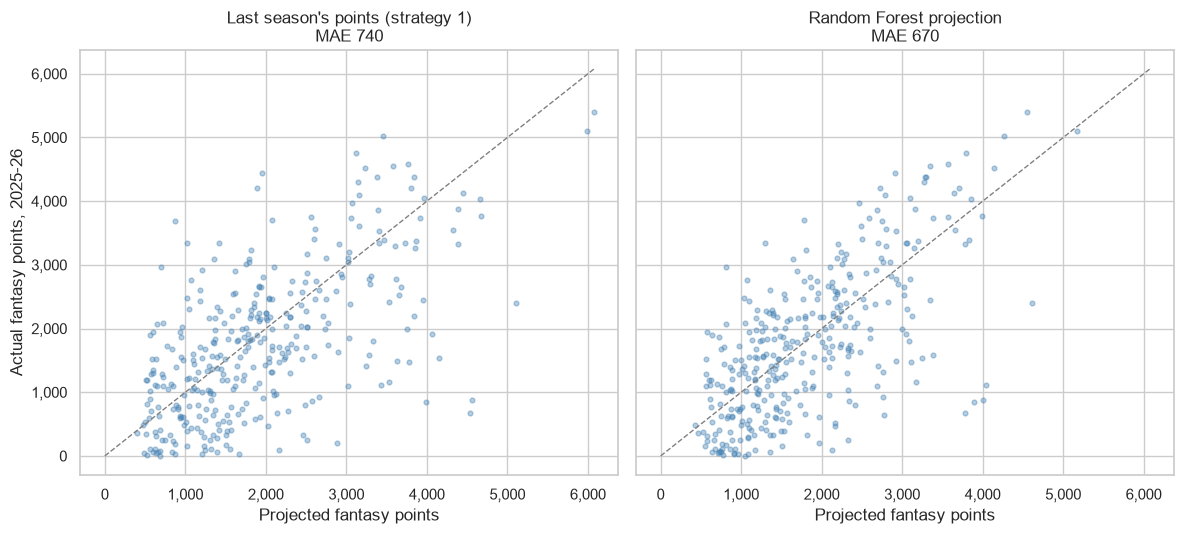

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
panels = [
    ("Last season's points (strategy 1)", test["FANTASY_PTS_LAG1"]),
    ("Random Forest projection", calibrated["PROJ_MID"]),
]
top = max(test[TARGET].max(), test["FANTASY_PTS_LAG1"].max(), calibrated["PROJ_MID"].max())
for ax, (label, projected) in zip(axes, panels):
    mae = evaluate(test[TARGET], projected)["MAE"]
    ax.scatter(projected, test[TARGET], s=12, alpha=0.4, color="steelblue")
    ax.plot([0, top], [0, top], color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"{label}\nMAE {mae:,.0f}")
    ax.set_xlabel("Projected fantasy points")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[0].set_ylabel(f"Actual fantasy points, {config.TEST_SEASON}")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
fig.savefig(config.PROJECT_ROOT / "outputs" / "projected_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

## Feature importance

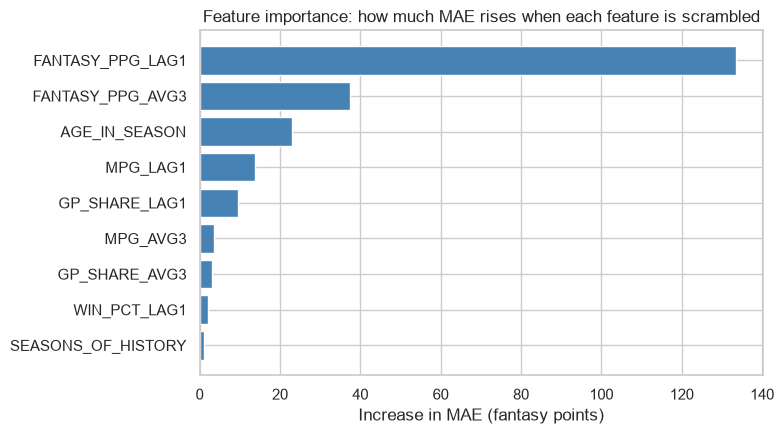

FANTASY_PPG_LAG1      134.0
FANTASY_PPG_AVG3       38.0
AGE_IN_SEASON          23.0
MPG_LAG1               14.0
GP_SHARE_LAG1          10.0
MPG_AVG3                4.0
GP_SHARE_AVG3           3.0
WIN_PCT_LAG1            2.0
SEASONS_OF_HISTORY      1.0


In [12]:
importance = permutation_importance(
    rf, test[MODEL_FEATURES], test[TARGET],
    scoring="neg_mean_absolute_error", n_repeats=10, random_state=config.RANDOM_SEED,
)
importance = pd.Series(importance.importances_mean, index=MODEL_FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance.index, importance.values, color="steelblue")
ax.set_title("Feature importance: how much MAE rises when each feature is scrambled")
ax.set_xlabel("Increase in MAE (fantasy points)")
fig.tight_layout()
fig.savefig(config.PROJECT_ROOT / "outputs" / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(importance.round(0).sort_values(ascending=False).to_string())

Importance is calculated by randomly shuffling the input feature and then rescoring the model to see by how much its MAE increases. As expected, the most important features are average points per game from the previous season and the weighted average of the previous 3 seasons, followed by the player's age.

## Biggest misses

In [13]:
base = build_base_table()
actual_games = base.loc[base["SEASON"] == config.TEST_SEASON, ["PLAYER_ID", "GP", "TEAM_GAMES"]]

misses = test[["PLAYER_ID", "PLAYER_NAME", "AGE_IN_SEASON", "GP_SHARE_LAG1"]].join(calibrated[["PROJ_MID", TARGET]])
misses = misses.merge(actual_games, on="PLAYER_ID", how="left")
misses["GP_SHARE_ACTUAL"] = misses["GP"] / misses["TEAM_GAMES"]
misses["MISS"] = misses[TARGET] - misses["PROJ_MID"]

columns = ["PLAYER_NAME", "AGE_IN_SEASON", "PROJ_MID", TARGET, "MISS", "GP_SHARE_LAG1", "GP_SHARE_ACTUAL"]
print("Biggest overprojections (scored less than projected):")
print(misses.nsmallest(10, "MISS")[columns].round(2).to_string(index=False))
print("\nBiggest underprojections (scored more than projected):")
print(misses.nlargest(10, "MISS")[columns].round(2).to_string(index=False))

worst_25 = misses.nsmallest(25, "MISS")
print(f"\nShare of team games played in {config.TEST_SEASON}: "
      f"25 biggest overprojections {worst_25['GP_SHARE_ACTUAL'].median():.0%} vs. all players {misses['GP_SHARE_ACTUAL'].median():.0%} (medians)")

Biggest overprojections (scored less than projected):
          PLAYER_NAME  AGE_IN_SEASON  PROJ_MID  TARGET_PTS     MISS  GP_SHARE_LAG1  GP_SHARE_ACTUAL
         Jayson Tatum           28.0   4005.85         878 -3127.85           0.88             0.20
           Trae Young           27.0   3785.37         679 -3106.37           0.93             0.18
     Domantas Sabonis           30.0   3897.39         841 -3056.39           0.85             0.23
        Anthony Davis           33.0   4045.34        1108 -2937.34           0.62             0.24
Giannis Antetokounmpo           31.0   4611.89        2399 -2212.89           0.82             0.44
      Dejounte Murray           29.0   2777.38         636 -2141.38           0.38             0.17
       Walker Kessler           24.0   2330.56         245 -2085.56           0.71             0.06
         Bradley Beal           33.0   2123.17          87 -2036.17           0.65             0.07
          Jalen Green           24.0   3168.22

The last line confirms that most big misses are due to injuries, because the much lower games played share of 28% compared to the average of 73% is most often explained by an injury.